# Solving Durablemodel with Search in infinite horizon

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import copy
import time
import datetime
from pathlib import Path

start_time = time.time()

from DurableModel import DurableConsumer
from HARK.ConsumptionSaving.ConsIndShockModel import utility_inv

FIG_DIR = Path("../Figures/DurableModel")
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
### Baseline parameters for all models

durable_defaults = dict(
    CRRA=2.0,
    DiscFac=0.975,
    LivPrb=1.0,
    alpha=0.75,
    d_ubar=1e-4,
    dDepr=0.05,
    adjC=0.3,
    MaintCost=0.0,
    OpCost=0.0,
    Rfree=1.04**(0.25),
    RSpread=0.0,
    PermGroFac=1.0,
    LTV=0.0,
    BoroCnstArt=0.0,
    # Income
    PermShkStd=0.0,
    PermShkCount=1,
    TranShkStd=0.2,
    TranShkCount=7,
    UnempPrb=0.0,
    IncUnemp=0.0,
    IncUnemp_Std=0.1,
    truncation=2,
    taxrate=0.0,
    labor=1.0,
    wage=1.0,
    # Channels (EV taste sigma_eps vs search are mutually exclusive)
    sigma_eps=0.0,
    SearchCost=0.1,
    ScaleBool=False,
    e_grid_count=101,
    PriceShkCount=5,
    PriceShkStd=0.1,
    # EoP method
    use_expected=True,
    use_TransitionMatrix=False,
    # Grids
    nNrmMax=5.0,
    nNrmCount=100,
    mNrmMax=8.0,
    mNrmCount=100,
    xNrmMax=13.0,
    xNrmCount=200,
    aNrmMax=8.0,
    aNrmCount=100,
    NestFac=1,
    grid_type="exp_mult",
    TranMatrix_mCount=1010,
    TranMatrix_bCount=1000,
    N_scan=800,
    cycles=0,
    T_cycle=1,       # number of periods before terminal when cycles >= 1
    tol=1e-6,        # infinite-horizon convergence tolerance (matches background)
    max_cycles=300,  # iteration cap for cycles=0 (matches background max_cycles)
    distance_metric="mse",
    verbose=False,
)


In [ ]:
base_search = copy.deepcopy(durable_defaults)
base_search["sigma_eps"] = 0.0
base_search["PriceShkStd"] = 0.0
base_search["PriceShkCount"] = 1
base_search["SearchCost"] = 0.3
base_search["cycle"] = 0
base_search["TranMatrixmCount"] = 250
base_search["diagnostics"] = False     # in your notebook config

search_model = DurableConsumer(**base_search)
search_model.update()
search_model.solve()

c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel.py:544: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel.py:551: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))
c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel.py:551: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha

1000.0
0.2547053462535234
0.06908311866915569
0.027082859401667894
0.013164851300091419
0.007591697693871101
0.0048097280789602
0.003290780397296186
0.0024916084943947666
0.0018512832163048946
0.0015712367124700918
0.0012965413273079813
0.0033711533284730023
0.003091483295103961
0.004420265153290554
0.0034381382018565487
0.00494944756206357
0.008869051245043984
0.005952513419604207
0.0034121040791829757
0.12032411262528532
0.06371568518561475
0.08840318783460777
0.116785516429272
0.11548685732639653
0.11998962753681981
0.12204174561109936
0.11616312258061667
0.10300482443116643


c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\utility.py:552: RuntimeWarning: divide by zero encountered in power
  return shocks[0] ** (-CRRA) * (
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel.py:1210: RuntimeWarning: invalid value encountered in subtract
  return self.CRRAutilityPD(c, d) - price * eop1 + eopd


0.105362076522956
0.10710313495531772
0.08881861806146595
0.06785233034881615
0.05693593505097069
0.04190416335494935
0.03149574499942549
0.023598266754245218
0.019520676754173
0.01551404951751003
0.013013300241166082
0.010930670521788777
0.009161131040427112
0.0075319522565404735
0.006498382753669239
0.006744791245330163
0.004863099612078113
0.0036836074174693956
0.0030537714718045453
0.0021631070443005503
0.001692198336243984
0.0010923200053683836
0.0007048356029216192
0.0005973406830568572
0.00037684455566178594
0.00029759858630135734
0.0003015458701532384
0.00041970893383451284
0.00035108882104893934
0.0002678015785349543
0.0003016577602838325
0.0003409393912514371
0.0002095833496541127
0.0001114072003635221
0.00012152096142095275
0.00010290249438579436
1.6239324834241447e-05
4.8450975978699346e-05
7.3308552028344404e-06
9.685534865641734e-05
1.3737103903492524e-05
1.2944075125413237e-05
4.275339297817877e-06
5.931735606100653e-06
3.2861723576193018e-06
1.1283566122262288e-06
1.952

In [ ]:
search_model.compute_steady_state()

In [ ]:
print("Steady-state aggregates:")
print(f"  Consumption SS (C):        {search_model.C_ss:.6f}")
print(f"  Durable stock SS (D):      {search_model.D_ss:.6f}")
print(f"  Durable expenditure (DEX): {search_model.DEX_ss:.6f}")
print(f"  Total expenditure (TEX):   {search_model.TEX_ss:.6f}")
print(f"  Assets SS (A):             {search_model.A_ss:.6f}")
print(f"  Adjustment share (ADJ):    {search_model.ADJ_ss:.6f}")

c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\scipy\sparse\_index.py:151: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray(i, j, x)


Steady-state aggregates:
  Consumption SS (C):        0.971686
  Durable stock SS (D):      0.310909
  Durable expenditure (DEX): 0.015545
  Total expenditure (TEX):   0.987232
  Assets SS (A):             0.074398
  Adjustment share (ADJ):    0.164055


In [7]:
import matplotlib.pyplot as plt

T = 50
J_C, J_DEX, J_TEX, J_D, J_A, J_ADJ = search_model.calc_jacobian("Rfree", T)

jacobians = {
    "C": J_C,
    "DEX": J_DEX,
    "TEX": J_TEX,
    "D": J_D,
    "A": J_A,
    "ADJ": J_ADJ,
}


c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel.py:551: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel.py:544: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)


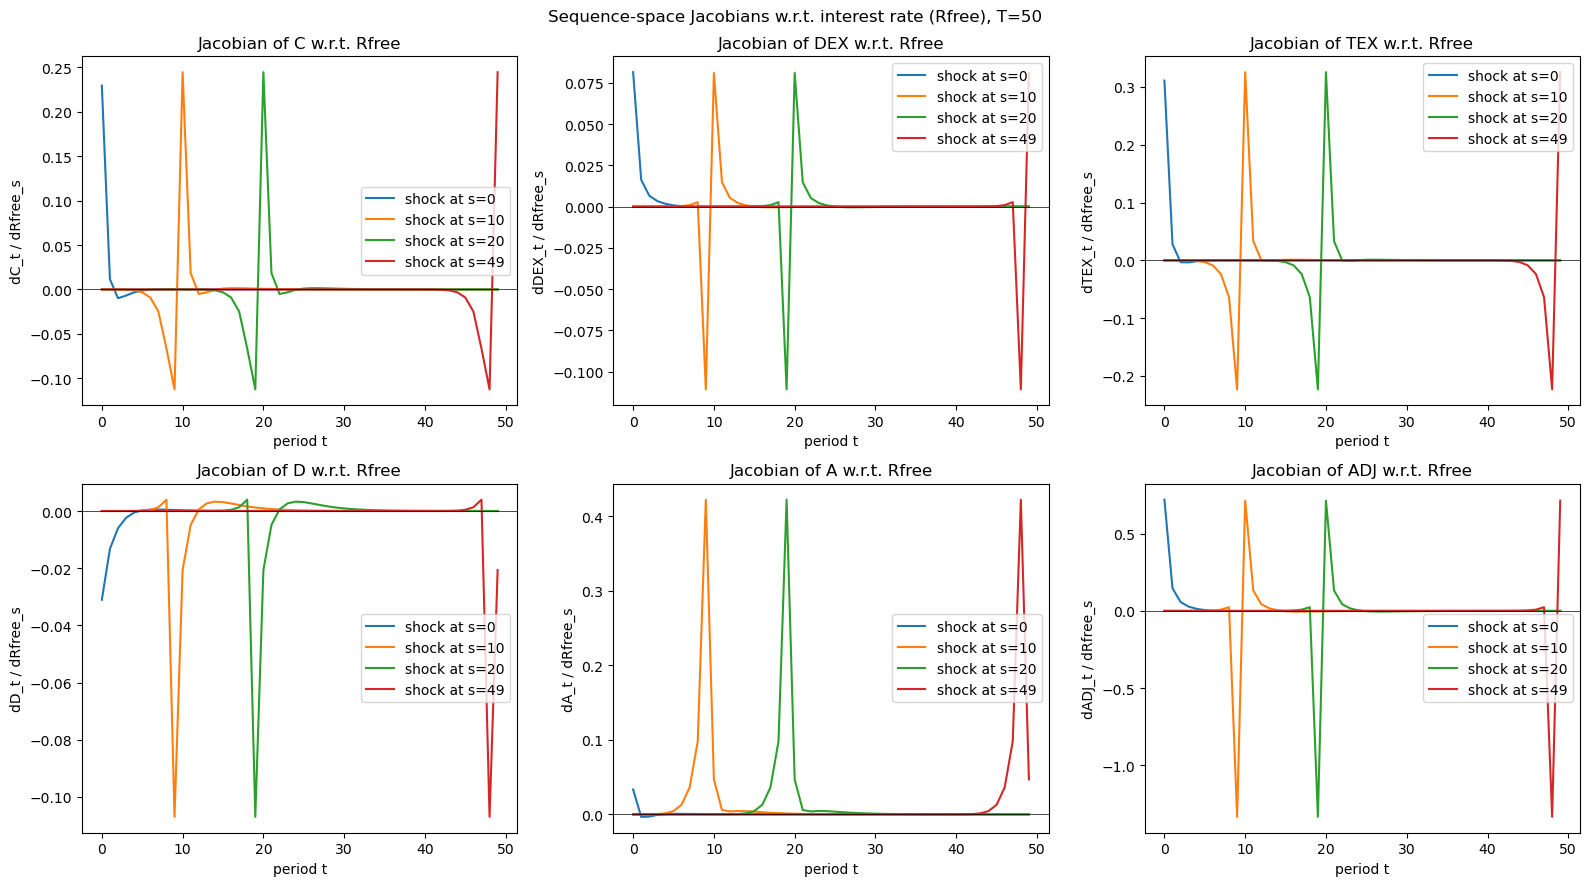

In [8]:
cols = [0, 10, 20, 49]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (name, J) in zip(axes.flat, jacobians.items()):
    for s in cols:
        ax.plot(J[:, s], label=f"shock at s={s}")
    ax.axhline(0.0, color="k", lw=0.5)
    ax.set_title(f"Jacobian of {name} w.r.t. Rfree")
    ax.set_xlabel("period t")
    ax.set_ylabel(f"d{name}_t / dRfree_s")
    ax.legend()
fig.suptitle("Sequence-space Jacobians w.r.t. interest rate (Rfree), T=50")
fig.tight_layout()
plt.show()